# Card 06 – Purchasing & imports
**Question:** do we buy what we sell?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

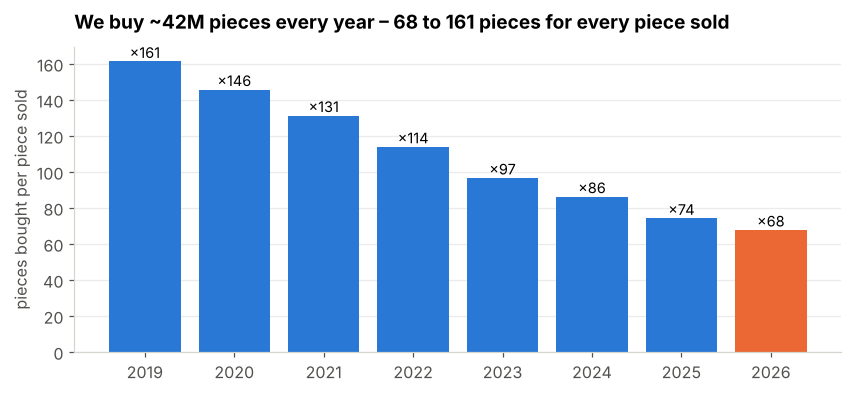

,sold,bought,purchase_spend_M,cost_of_goods_sold_M,bought_per_sold,spend_per_cogs
fy,,,,,,
2019,253025,40796083,1284.0,11.8,161.2,108.7
2020,289688,42185241,1502.7,15.2,145.6,99.1
2021,325375,42683780,1672.9,19.1,131.2,87.6
2022,375763,42769577,2168.8,28.7,113.8,75.7
2023,436420,42130702,3006.0,45.8,96.5,65.7
2024,500525,43125833,4630.7,80.6,86.2,57.4
2025,567644,42074944,6457.2,130.3,74.1,49.6
2026,620701,41989793,8105.2,178.3,67.6,45.5


In [2]:
li, pl, po = full_years(files['lines']), full_years(files['po_lines']), full_years(files['pos'])
y = pd.DataFrame({'sold': li.groupby('fy').quantity.sum(), 'bought': pl.groupby('fy').quantity.sum(),
                  'purchase_spend_M': pl.groupby('fy').line_cost_EGP.sum() / 1e6, 'cost_of_goods_sold_M': li.groupby('fy').cost_line_EGP.sum() / 1e6})
y['bought_per_sold'] = y.bought / y.sold
y['spend_per_cogs'] = y.purchase_spend_M / y.cost_of_goods_sold_M
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(y.index, y.bought_per_sold, color=[ORANGE if v == y.index[-1] else BLUE for v in y.index])
for x, v in y.bought_per_sold.items():
    ax.text(x, v + 2, f'×{v:.0f}', ha='center', fontsize=9.5)
ax.set_xticks(y.index)
style(ax, f'We buy ~42M pieces every year – {y.bought_per_sold.min():.0f} to {y.bought_per_sold.max():.0f} pieces for every piece sold', 'pieces bought per piece sold')
save(fig, 'c06_bought_per_sold')
y.round(1)

bought per SKU: 341,864 – 658,974 | sold per SKU: 926 – 11,637


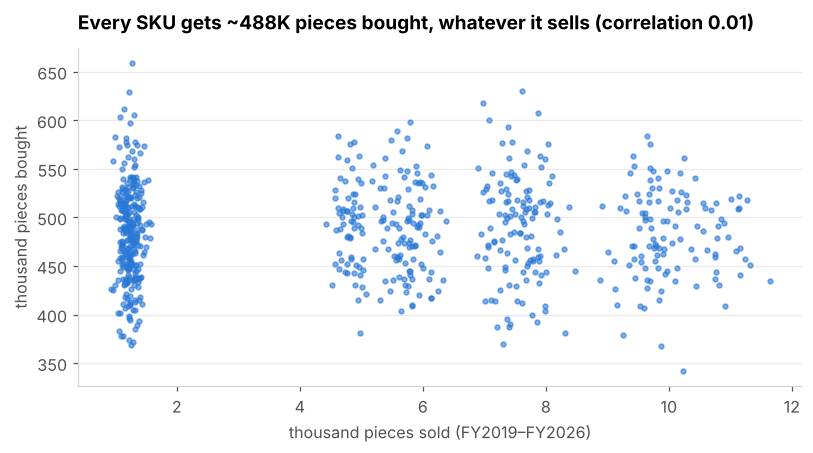

In [3]:
s = pd.DataFrame({'sold': li.groupby('sku_id').quantity.sum(), 'bought': pl.groupby('sku_id').quantity.sum()}).dropna()
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(s.sold / 1e3, s.bought / 1e3, s=10, color=BLUE, alpha=0.6)
style(ax, f'Every SKU gets ~{s.bought.median() / 1e3:.0f}K pieces bought, whatever it sells (correlation {s.corr().iloc[0, 1]:.2f})', 'thousand pieces bought')
ax.set_xlabel('thousand pieces sold (FY2019–FY2026)')
save(fig, 'c06_sku_bought_vs_sold')
print(f'bought per SKU: {s.bought.min():,.0f} – {s.bought.max():,.0f} | sold per SKU: {s.sold.min():,.0f} – {s.sold.max():,.0f}')

In [4]:
print('purchase unit cost ÷ sales unit cost (same SKU):', round((pl.groupby('sku_id').unit_cost_EGP.mean() / li.groupby('sku_id').unit_cost_EGP.mean()).mean(), 2))
print('lead time (PO → delivery):', pl.lead_days.describe()[['min', '50%', 'max']].to_dict(), '– spread evenly = random')
cnt = po.groupby('supplier_id').size()
print(f'{po.supplier_id.nunique()} suppliers, each with {cnt.min()}–{cnt.max()} purchase orders (no main supplier)')
print('PO purpose shares:', (po.po_purpose.value_counts(normalize=True) * 100).round(1).to_dict())
(files['suppliers'].material_type.value_counts()).to_frame('suppliers by declared type')

purchase unit cost ÷ sales unit cost (same SKU): 0.7
lead time (PO → delivery): {'min': 3.0, '50%': 29.0, 'max': 55.0} – spread evenly = random
48 suppliers, each with 814–921 purchase orders (no main supplier)
PO purpose shares: {'Store network stock': 33.6, 'Finished goods replenishment': 33.4, 'Seasonal procurement': 33.0}


,suppliers by declared type
material_type,
Packaging,5
Accessories,5
Finished garments,5
Elastic & Lycra,5
Labels,5
Machinery services,5
Knitted fabric,5
Dyes,5
Logistics,4


In [5]:
im = full_years(files['imports'])
print('imports per year (M USD):', (im.groupby('fy').customs_value_USD.sum() / 1e6).round(1).to_dict())
print('freight by container (USD):', im.groupby('container_type').freight_USD.mean().round(0).to_dict())
print('duty rate: %.0f%%–%.0f%%, spread evenly' % ((im.duty_and_tax_USD / im.customs_value_USD).min() * 100, (im.duty_and_tax_USD / im.customs_value_USD).max() * 100))
print('import shipments carry no quantity and no SKU → they cannot be linked to stock or sales')

imports per year (M USD): {2019: 55.9, 2020: 54.5, 2021: 56.3, 2022: 57.0, 2023: 59.2, 2024: 55.7, 2025: 56.5, 2026: 52.1}
freight by container (USD): {'20FT': 6141.0, '40FT': 6158.0}
duty rate: 0%–20%, spread evenly
import shipments carry no quantity and no SKU → they cannot be linked to stock or sales


### Takeaway (card 06)
- The company buys a **fixed ~42M pieces a year** (68–161× sales), spread equally over SKUs (correlation 0.01) and suppliers.
  Purchase spend (8.1B EGP in FY2026) is ~45× the cost of what was sold – so either the unit is not "piece" or these POs are not real purchases → **question for the company**.
- What we can trust: purchase unit cost is ~70% of the sales unit cost.
- Lead times, supplier types, import freight and duty look random → no supplier scorecard or landed-cost model from this data.
- Fix: buy from the **demand forecast** (notebook 12): forecast + safety stock − stock on hand, per category and month.